# Decision tree

A single classification tree for predicting whether an unplanned New York hospital
admission lasts more than 7 days. Decisions are in
`docs/notes/2026-11-10-model-comparison-plan.md` and
`docs/notes/2026-11-12-decision-tree.md`. The data, cohort, split, cleaning and encoder
come from `analysis/common.py`, and `analysis/baseline_model.py` walks through them.

In [1]:
import re
import textwrap
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

from analysis import common

RESULTS_DIR = common.RESULTS_DIR / "decision_tree"

## Setup

The same training set, features and folds as the baseline. The recalibration set is
only used in Recalibration, where the final model predicts on it. The test set isn't used
yet.

In [2]:
train, recal, test = common.load_splits()
X, y = train[common.FEATURES], train["y"]
print(f"{len(train):,} training stays, {y.mean():.1%} stayed more than 7 days")
print(f"{len(common.FEATURES)} features")

360,000 training stays, 23.1% stayed more than 7 days
17 features


## Tuning

### The model

A classification tree splits the stays again and again, each time on the yes/no
question that best separates long stays from short ones by Gini impurity. A stay's risk
is the share of long stays in the leaf it ends up in. With full one-hot encoding, each
split separates one level of a feature from the rest.

Two settings control the tree's size:

- **`min_samples_leaf`** is the fewest training stays a leaf may hold. Small leaves give
  noisy risks near 0 or 1. Large leaves give few distinct risks, which costs AUC.
- **`ccp_alpha`** prunes the grown tree back. A split is kept only if it lowers the
  tree's average Gini impurity by at least α. `ccp_alpha = 0` is no pruning. The root
  impurity is about 2 × 0.23 × 0.77 ≈ 0.35, so useful values of α are small.

One grid covers both:

- `ccp_alpha` in {0, 1e-5, 3e-5, 1e-4, 3e-4}
- `min_samples_leaf` in {1, 3, 6, 12, 25, 50, 100, 200, 400, 800}

That's 50 settings × 5 folds = 250 fits. Every other setting keeps its default,
including the Gini criterion. There's no `class_weight`, since reweighting the classes
would distort the risks.

In [3]:
CCP_ALPHAS = [0.0, 1e-5, 3e-5, 1e-4, 3e-4]
MIN_SAMPLES_LEAF = [1, 3, 6, 12, 25, 50, 100, 200, 400, 800]


def make_model(ccp_alpha, min_samples_leaf):
    return DecisionTreeClassifier(
        ccp_alpha=ccp_alpha,
        min_samples_leaf=min_samples_leaf,
        random_state=common.SEED,
    )

### Fits

`common.encode_folds` fits the encoder on each fold's training part only. The encoder
doesn't depend on the tree's settings, so each fold is encoded once and reused for all
50 settings.

The 250 fits run in parallel. For each one we save the validation AUC, Brier,
precision and recall, the tree's depth and number of leaves, and the fit time. To
recompute, delete `results/decision_tree/tuning.csv`.

In [4]:
def fit_one(fold, ccp_alpha, min_samples_leaf, return_risk=False):
    """Fit one setting on one fold and score it on the validation part."""
    model = make_model(ccp_alpha, min_samples_leaf)
    start = time.perf_counter()
    model.fit(fold["X_fit"], fold["y_fit"])
    seconds = time.perf_counter() - start
    risk = model.predict_proba(fold["X_validation"])[:, 1]
    scores = {
        "ccp_alpha": ccp_alpha,
        "min_samples_leaf": min_samples_leaf,
        **common.fold_scores(
            fold["fold"],
            fold["y_validation"],
            risk,
            seconds,
            depth=model.get_depth(),
            leaves=model.get_n_leaves(),
        ),
    }
    return (scores, risk) if return_risk else scores


def run_tuning():
    folds = common.encode_folds(X, y)
    rows = Parallel(n_jobs=-1, verbose=5)(
        delayed(fit_one)(fold, ccp_alpha, min_samples_leaf)
        for ccp_alpha in CCP_ALPHAS
        for min_samples_leaf in MIN_SAMPLES_LEAF
        for fold in folds
    )
    return {"tuning": pd.DataFrame(rows)}


tuning = common.load_or_compute(
    {"tuning": RESULTS_DIR / "tuning.csv"}, run_tuning
)["tuning"]

assert len(tuning) == len(CCP_ALPHAS) * len(MIN_SAMPLES_LEAF) * common.FOLDS.get_n_splits()
print(f"{tuning['seconds'].sum() / 60:.0f} minutes of fitting in total")

Loaded saved results
117 minutes of fitting in total


### Tuning curve

Mean and SD of each score across the 5 folds, for every setting, with the tree's mean
depth and number of leaves. The baseline's CV AUC and Brier, from
`results/baseline_logistic/cv_scores.csv`, are the reference.

In [5]:
summary = (
    tuning.groupby(["ccp_alpha", "min_samples_leaf"])
    .agg(
        auc=("auc", "mean"),
        auc_sd=("auc", "std"),
        brier=("brier", "mean"),
        brier_sd=("brier", "std"),
        depth=("depth", "mean"),
        leaves=("leaves", "mean"),
        seconds=("seconds", "mean"),
    )
    .reset_index()
)

baseline_scores = pd.read_csv(common.RESULTS_DIR / "baseline_logistic" / "cv_scores.csv")
baseline_auc = baseline_scores["auc"].mean()
baseline_brier = baseline_scores["brier"].mean()
print(f"Baseline: AUC {baseline_auc:.4f}, Brier {baseline_brier:.4f}")

common.show_scores(summary)

Baseline: AUC 0.7734, Brier 0.1447
 ccp_alpha  min_samples_leaf    auc    auc_sd  brier  brier_sd  depth    leaves  seconds
         0                 1 0.6206  0.002133 0.2617   0.00152  161.2 7.048e+04    76.64
         0                 3 0.6687  0.003676 0.1999  0.001392  158.8 4.346e+04    56.27
         0                 6 0.7008  0.003337 0.1741  0.001141  138.6 2.645e+04    47.83
         0                12 0.7268    0.0035 0.1597  0.001027    126 1.486e+04    37.97
         0                25 0.7429  0.002223  0.152 0.0005601  105.2      7620    28.74
         0                50 0.7512   0.00195 0.1488 0.0004558   92.2      3940    17.25
         0               100 0.7536  0.002159 0.1481 0.0005929   67.2      2002    11.52
         0               200 0.7507  0.002691 0.1487 0.0006706   59.6      1018    6.685
         0               400 0.7474  0.002648 0.1495 0.0006493   43.6     524.8    4.061
         0               800 0.7381  0.002085 0.1515 0.0004872   29.8     2

The plot shows CV AUC and Brier against `ccp_alpha`, one line per leaf size. α = 0
can't go on a log scale, so the x-axis is symlog: linear between 0 and 1e-5, log above.
To keep it readable, it shows 6 of the 10 leaf sizes. The table above has them all.

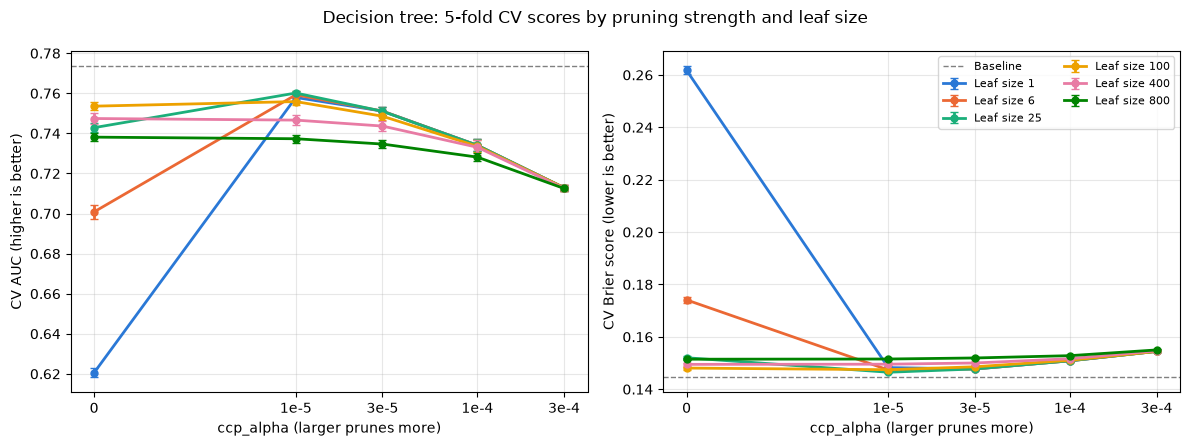

In [6]:
PLOTTED_LEAF_SIZES = [1, 6, 25, 100, 400, 800]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, score, baseline_value, label in [
    (axes[0], "auc", baseline_auc, "CV AUC (higher is better)"),
    (axes[1], "brier", baseline_brier, "CV Brier score (lower is better)"),
]:
    ax.axhline(baseline_value, color="gray", linestyle="--", linewidth=1, label="Baseline")
    for leaf_size, color in zip(PLOTTED_LEAF_SIZES, COLORS):
        rows = summary[summary["min_samples_leaf"] == leaf_size]
        ax.errorbar(
            rows["ccp_alpha"],
            rows[score],
            yerr=rows[f"{score}_sd"],
            color=color,
            marker="o",
            markersize=5,
            linewidth=2,
            capsize=3,
            label=f"Leaf size {leaf_size}",
        )
    ax.set_xscale("symlog", linthresh=1e-5)
    ax.set_xticks(CCP_ALPHAS, ["0", "1e-5", "3e-5", "1e-4", "3e-4"])
    ax.set_xlabel("ccp_alpha (larger prunes more)")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[1].legend(loc="upper right", fontsize=8, ncol=2)
fig.suptitle("Decision tree: 5-fold CV scores by pruning strength and leaf size")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "tuning.png", dpi=150)

### Best setting for each leaf size

The `ccp_alpha` with the highest mean CV AUC at each leaf size, with each score's
difference from the baseline. The best overall is `ccp_alpha = 1e-5` with a leaf size of
25. Neither is at an edge of its range, so the grid isn't extended.

Darker shading is better: higher AUC, lower Brier. The best value in each shaded column
is in bold.

In [7]:
best = summary.loc[summary.groupby("min_samples_leaf")["auc"].idxmax()].copy()
best["auc_vs_baseline"] = best["auc"] - baseline_auc
best["brier_vs_baseline"] = best["brier"] - baseline_brier
common.show_scores(
    best[
        [
            "min_samples_leaf",
            "ccp_alpha",
            "auc",
            "auc_sd",
            "auc_vs_baseline",
            "brier",
            "brier_sd",
            "brier_vs_baseline",
            "leaves",
        ]
    ],
    highlight=True,
)

min_samples_leaf,ccp_alpha,auc,auc_sd,auc_vs_baseline,brier,brier_sd,brier_vs_baseline,leaves
1,1e-05,0.7579,0.001285,-0.01549,0.1483,0.0005364,+0.00358,1418
3,1e-05,0.7583,0.001372,-0.01517,0.148,0.0005126,+0.00337,1367
6,1e-05,0.7593,0.001688,-0.01417,0.1474,0.0004995,+0.00268,1171
12,1e-05,0.7598,0.001482,-0.01365,0.1468,0.0004489,+0.00214,969.4
25,1e-05,0.7602,0.001161,-0.01327,0.1465,0.0003299,+0.00181,766.4
50,1e-05,0.7584,0.001653,-0.01507,0.1468,0.0004835,+0.00209,587.8
100,1e-05,0.7559,0.001873,-0.01754,0.1475,0.0005609,+0.00278,442.4
200,1e-05,0.751,0.002357,-0.02247,0.1486,0.0006535,+0.00393,315.6
400,0,0.7474,0.002648,-0.02600,0.1495,0.0006493,+0.00481,524.8
800,0,0.7381,0.002085,-0.03529,0.1515,0.0004872,+0.00678,263.2


### Chosen model

`ccp_alpha = 1e-5` with a leaf size of 25, the best mean CV AUC. It also has the lowest
Brier.

#### Out-of-fold predictions

The tuning step only saved scores, so we refit the chosen setting on the same 5 folds
to get one out-of-fold risk for each training stay. The fits are deterministic, so
the scores must match the tuning rows. To recompute, delete `cv_scores.csv` and
`oof_predictions.parquet`.

In [8]:
CHOSEN = {"ccp_alpha": 1e-5, "min_samples_leaf": 25}
top = summary.loc[summary["auc"].idxmax()]
assert (top["ccp_alpha"], top["min_samples_leaf"]) == tuple(CHOSEN.values()), "CHOSEN isn't the best setting"


def run_chosen_cv():
    folds = common.encode_folds(X, y)
    fits = Parallel(n_jobs=-1)(
        delayed(fit_one)(fold, **CHOSEN, return_risk=True) for fold in folds
    )
    return {
        "scores": pd.DataFrame([scores for scores, _ in fits]),
        "predictions": common.oof_frame(train.index, folds, [risk for _, risk in fits]),
    }


chosen_cv = common.load_or_compute(
    {
        "scores": RESULTS_DIR / "cv_scores.csv",
        "predictions": RESULTS_DIR / "oof_predictions.parquet",
    },
    run_chosen_cv,
)
cv_scores = chosen_cv["scores"]
oof_predictions = chosen_cv["predictions"]

common.check_rows(oof_predictions, train)
tuned = tuning[
    (tuning["ccp_alpha"] == CHOSEN["ccp_alpha"])
    & (tuning["min_samples_leaf"] == CHOSEN["min_samples_leaf"])
]
for column in ["auc", "leaves"]:
    assert np.allclose(cv_scores[column], tuned.sort_values("fold")[column])
common.show_scores(cv_scores)

Loaded saved results
 ccp_alpha  min_samples_leaf  fold    auc  brier  precision  recall  depth  leaves  seconds
     1e-05                25     1 0.7616  0.146     0.4049  0.6648     49     796    23.45
     1e-05                25     2 0.7602 0.1466     0.4072  0.6479     47     756    23.18
     1e-05                25     3 0.7597 0.1464     0.4049  0.6596     51     774    23.17
     1e-05                25     4 0.7585 0.1467     0.4028   0.661     44     755    23.42
     1e-05                25     5 0.7607 0.1467     0.4104  0.6571     46     751    22.72


#### Results

The same results table as the baseline's. Each score is the mean and SD across the 5
validation folds. Precision and recall use the same base-rate threshold as the
baseline (`common.THRESHOLD`). They're for awareness only, and we don't use them to
choose models.

In [9]:
common.check_threshold(train)
results = common.cv_results("Decision tree", cv_scores)
common.show_scores(results)

        model    auc   auc_sd  brier  brier_sd  precision  precision_sd  recall  recall_sd
Decision tree 0.7602 0.001161 0.1465 0.0003299      0.406      0.002877  0.6581   0.006319


## Final model

The encoder and tree refit on all of train. To refit, delete `model.joblib`.

In [10]:
def fit_final_model():
    model = make_pipeline(common.make_encoder(), make_model(**CHOSEN))
    model.fit(X, y)
    return {"model": model}


final_model = common.load_or_compute(
    {"model": RESULTS_DIR / "model.joblib"}, fit_final_model
)["model"]
tree = final_model[-1]
assert (tree.ccp_alpha, tree.min_samples_leaf) == tuple(CHOSEN.values()), "Saved model is out of date"
print(f"Final tree: depth {tree.get_depth()}, {tree.get_n_leaves()} leaves")

Loaded saved results
Final tree: depth 45, 697 leaves


### Encoded columns

Each encoded column is one level of one feature. To read the tree, each column gets a
label: the feature and the level, with the description for codes (diagnosis, MDC and
facility). Rare levels grouped by the encoder are "Other".

In [11]:
DESCRIPTIONS = {
    "ccsr_diagnosis_code": "ccsr_diagnosis_description",
    "apr_mdc_code": "apr_mdc_description",
    "permanent_facility_id": "facility_name",
}
descriptions = {
    feature: train.drop_duplicates(feature).set_index(feature)[description]
    for feature, description in DESCRIPTIONS.items()
}


def source_feature(column):
    """The original feature an encoded column comes from."""
    return max((f for f in common.FEATURES if column.startswith(f + "_")), key=len)


def column_label(feature, level):
    if level == "infrequent_sklearn":
        level = "Other"
    elif feature in descriptions:
        description = textwrap.shorten(descriptions[feature][level], 32, placeholder="...")
        level = f"{level} ({description})"
    return f"{feature} = {level}"


encoder = final_model[0]
columns = pd.DataFrame({"column": encoder.get_feature_names_out()})
columns["feature"] = columns["column"].map(source_feature)
columns["level"] = [c[len(f) + 1 :] for c, f in zip(columns["column"], columns["feature"])]
columns["label"] = [column_label(f, level) for f, level in zip(columns["feature"], columns["level"])]
assert columns["feature"].nunique() == len(common.FEATURES)
print(f"{len(columns)} encoded columns")

632 encoded columns


### Readable tree

The top 3 levels of the final tree: its first 7 splits. Every split asks whether a stay
has one level of one feature. Each box shows its share of the training stays and the
share of those that stayed more than 7 days. Orange boxes are mostly short stays, blue
mostly long, and darker is more certain. The full tree goes on for 45 levels.

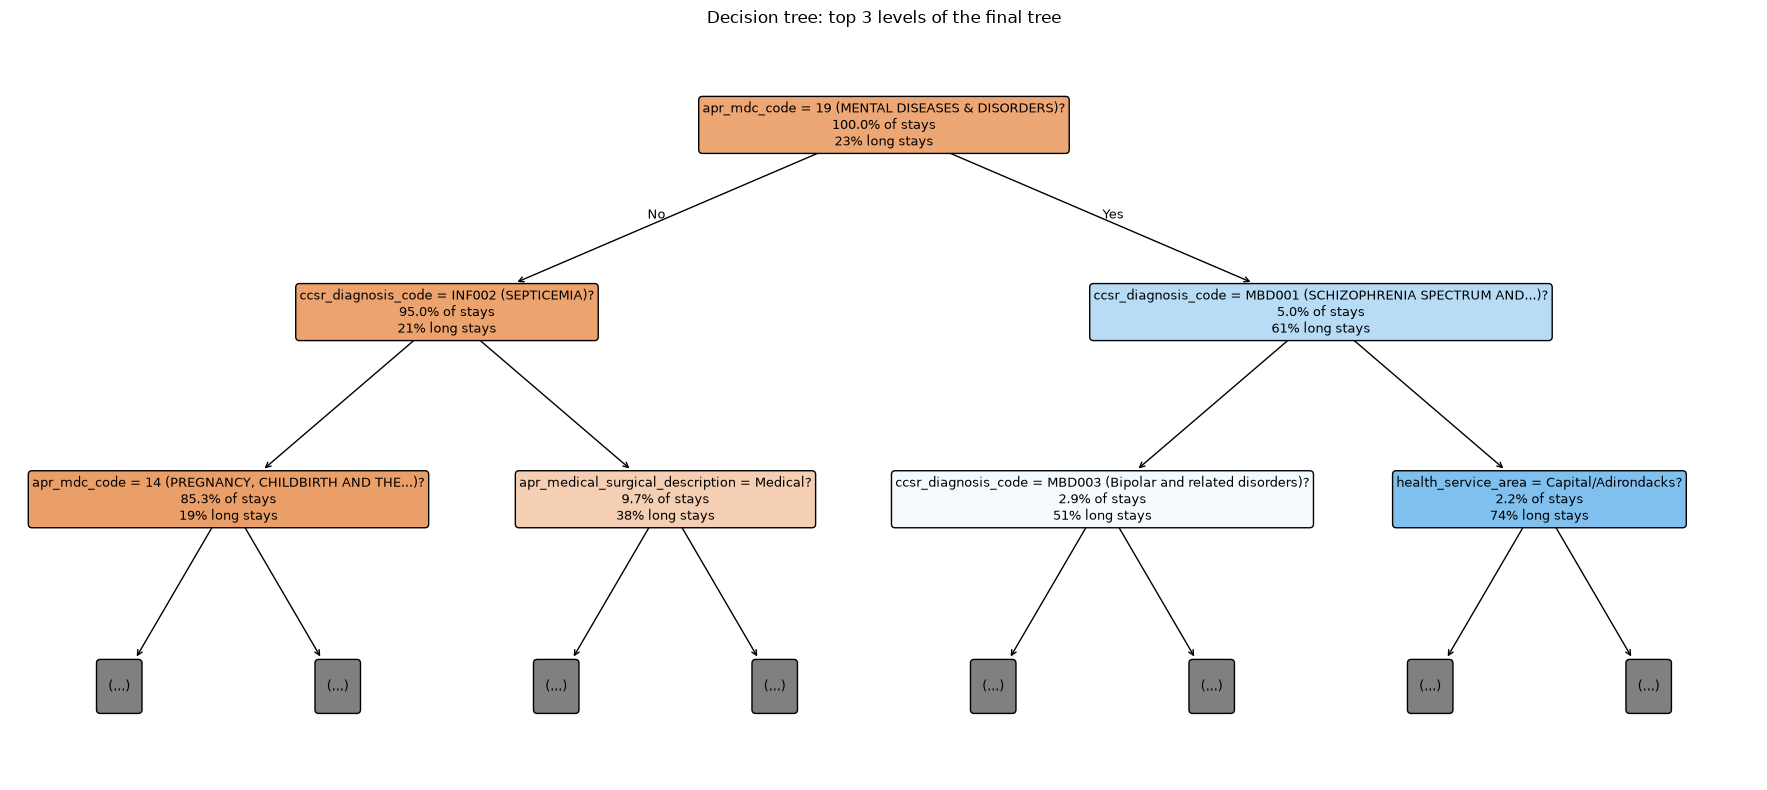

In [12]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    tree,
    max_depth=2,
    feature_names=columns["label"].tolist(),
    class_names=["≤ 7 days", "> 7 days"],
    filled=True,
    impurity=False,
    proportion=True,
    rounded=True,
    precision=2,
    fontsize=9,
    ax=ax,
)


def plain_text(text):
    """Reword plot_tree's box text: a question, the share of stays, the long-stay share."""
    if text.strip() in ("True", "False"):
        return {"True": "No", "False": "Yes"}[text.strip()]
    text = text.replace(" <= 0.5", "?")
    text = re.sub(r"samples = (\S+)", r"\1 of stays", text)
    text = re.sub(r"value = \[\S+, (\S+)\]", lambda m: f"{float(m[1]):.0%} long stays", text)
    return re.sub(r"\nclass = .*", "", text)


for label in ax.texts:
    label.set_text(plain_text(label.get_text()))
ax.set_title("Decision tree: top 3 levels of the final tree")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "tree.png", dpi=150)

### Feature importance

A split's importance is how much it lowers the impurity, weighted by the stays it
splits. A column's importance is the total over all splits on that column, and the
importances sum to 1. Adding up each feature's columns gives the total for each original
feature. This is exact, since each split is on exactly one column.

Two limits: impurity importance favours features with many levels, since they have
more chances to find a split that looks useful, and it's measured on the training data
the tree was fit to. So the order is a rough guide, especially for the diagnosis,
facility and ZIP code features, which have hundreds of levels.

In [13]:
columns["importance"] = tree.feature_importances_
importance = (
    columns.groupby("feature")
    .agg(importance=("importance", "sum"), columns=("column", "size"))
    .sort_values("importance", ascending=False)
    .reset_index()
)
importance["cumulative"] = importance["importance"].cumsum()
assert np.isclose(importance["importance"].sum(), 1)
common.show_scores(importance)

                         feature  importance  columns  cumulative
                    apr_mdc_code      0.3602       25      0.3602
             ccsr_diagnosis_code       0.299      265      0.6592
apr_medical_surgical_description      0.1175        3      0.7768
              payment_typology_1     0.04523       10       0.822
           permanent_facility_id     0.03951      175      0.8615
                       age_group     0.03192        5      0.8934
             health_service_area     0.02518        8      0.9186
                 hospital_county      0.0212       53      0.9398
               type_of_admission      0.0207        3      0.9605
  emergency_department_indicator     0.01227        2      0.9728
              payment_typology_2    0.007833       10      0.9806
                            race    0.006858        4      0.9874
                        zip_code    0.006583       51       0.994
                       ethnicity    0.002914        4      0.9969
          

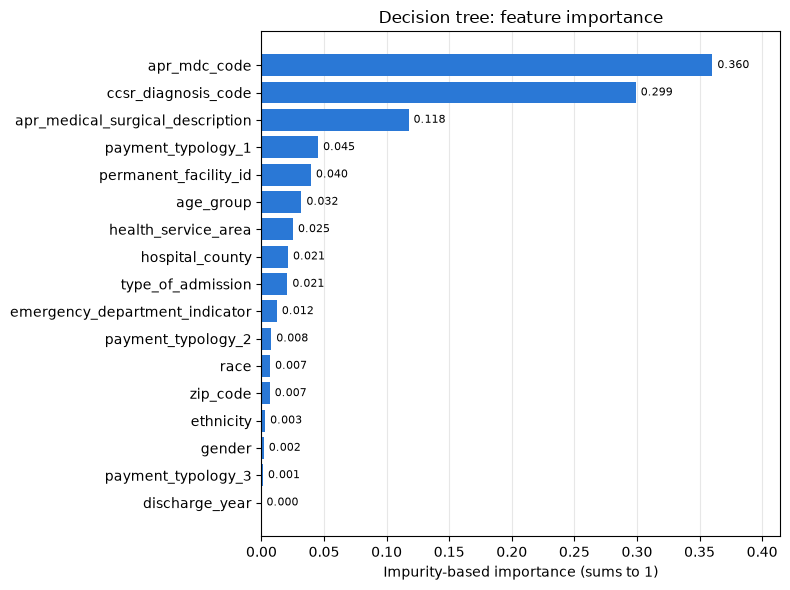

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance["feature"], importance["importance"], color="#2a78d6")
ax.invert_yaxis()
for y_position, value in enumerate(importance["importance"]):
    ax.text(value + 0.004, y_position, f"{value:.3f}", va="center", fontsize=8)
ax.set_xlim(0, importance["importance"].max() * 1.15)
ax.set_xlabel("Impurity-based importance (sums to 1)")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.set_title("Decision tree: feature importance")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_importance.png", dpi=150)

#### What the importances say

Long-stay rates below are from the training set, where 23% of stays run long.

- **What the patient is admitted for matters most.** MDC, CCSR diagnosis and medical vs
  surgical hold 78% of the importance. Mental health admissions (MDC 19) are the
  clearest signal: 5% of stays, and about 61% of them run long. That's why the tree
  splits on them first. At the other end, pregnancy and childbirth stays almost never
  run long (about 2%). Surgical stays run long more often than medical ones (32% vs
  21%).
- **MDC and CCSR diagnosis overlap.** MDC is a coarse grouping of diagnoses, so the two
  share credit. Whichever one the tree splits on first takes the importance, and the
  other gets less than it would on its own. Their combined 66% is more meaningful than
  the split between them.
- **Who the patient is matters much less.** Primary payer (4.5%) and age group (3.2%)
  come next. Medicare stays run long 27% of the time and commercial ones 15–17%, but
  Medicare patients are mostly over 65 and older patients run long more often (27% at
  70+ vs 14% under 18). So payer and age partly stand in for each other, and for
  health problems the data doesn't record.
- **Where the patient is treated adds a little.** Facility, health service area and
  county add up to about 9%. Long-stay rates vary across hospitals (from about 14% to
  30% for the middle 80% of hospitals with at least 500 stays), but much of that
  follows from which patients each hospital admits.
- **Demographics add almost nothing.** Race, ethnicity and gender together are about
  1%, and the tree never splits on discharge year: 2023 and 2024 have the same
  long-stay rate. Low importance for race doesn't mean the model treats racial groups
  the same, since other features can carry the same information. That's checked in the
  fairness analysis.

These describe what the tree uses to predict, not what causes long stays.

## Recalibration

### Platt scaling and isotonic regression

The final model predicts the recalibration set, and Platt scaling and isotonic
regression are fit on those risks with `common.fit_recalibrators`. Both are judged
only on the test set, in the comparison notebook. These steps take seconds, so they
rerun every time and overwrite the saved files.

A tree gives every stay in a leaf the same risk, so its risks take at most one value
per leaf. Isotonic regression sees a step-shaped input, and Platt scaling can't change
the order of the steps.

In [15]:
recal_predictions = common.predict_risk(final_model, recal)
common.check_rows(recal_predictions, recal)
recal_predictions.to_parquet(RESULTS_DIR / "recal_predictions.parquet")
print(
    f"{recal_predictions['risk'].nunique()} distinct risks on the recalibration set, "
    f"from {tree.get_n_leaves()} leaves"
)

recalibrators = common.fit_recalibrators(recal_predictions["risk"], recal["y"])
joblib.dump(recalibrators, RESULTS_DIR / "recalibrators.joblib")

632 distinct risks on the recalibration set, from 697 leaves


['results/decision_tree/recalibrators.joblib']

## Findings

Takeaways from the tuning results and the final tree above.

- **Chosen model: `ccp_alpha = 1e-5` with a leaf size of 25.** It has the best mean
  CV AUC (0.7602) and the lowest Brier (0.1465) in the grid. The fold trees have about
  770 leaves and the final tree, refit on all of train, has 697 leaves and depth 45.
- **The tree is clearly worse than logistic regression.** It trails the baseline on
  every fold, by 0.013–0.014 AUC and 0.0014–0.0020 Brier. A tree gives every stay in a
  leaf the same risk, and an effect that simply adds up across features, such as age
  on top of diagnosis, has to be rebuilt separately in each branch. Logistic regression
  gets those additive effects directly. With one-hot encoding, each split can also only
  separate one level from the rest. The random forest and XGBoost average many trees,
  which smooths the steps, and will show whether interactions add anything.
- **Pruning does most of the work.** Unpruned trees overfit badly: at a leaf size of 1
  the tree has about 70,000 leaves and an AUC of 0.62. `ccp_alpha = 1e-5` is the best α
  for every leaf size up to 200. At α = 3e-5 the tree has about 240 leaves and AUC
  0.751, and from 1e-4 up it has 70 leaves or fewer, which is too coarse (AUC
  0.71–0.73).
- **Leaf size matters little once the tree is pruned.** Leaf sizes 6–25 are within
  0.001 AUC, less than the fold-to-fold SD. The full tree pruned back with α alone
  (leaf size 1, the textbook method) is only 0.002 behind. The grid was extended down
  to a leaf size of 1 because 25 was at the edge of the first grid. 25 is still best.
- **Precision and recall.** At the base-rate threshold the tree's precision matches
  the lasso's (0.406), but it flags fewer of the actual long stays (recall 0.66 vs
  0.70).
- **Diagnosis drives the tree.** The first split is mental health (MDC 19): 5% of
  stays, of which 61% run long, against 21% for the rest. Schizophrenia, bipolar
  disorder, septicemia and pregnancy come next. MDC, CCSR diagnosis and medical vs
  surgical together hold 78% of the impurity importance. Payer and age come next, then
  location (facility, region, county, about 9% together). Race, ethnicity and gender
  add about 1%, and the tree never splits on discharge year. See What the importances
  say.
- **Importance is a rough guide.** Impurity importance favours features with many
  levels and is measured on training data, so the order of the smaller features
  shouldn't be read closely.
- **Recalibration.** The final tree gives 632 distinct risks on the recalibration set.
  Some leaves of 25 or more stays have no long stays, so they predict a risk of exactly
  0: 0.07% of the out-of-fold predictions. Platt clips those to 1e-6 before taking
  log-odds. Whether Platt or isotonic helps is judged on the test set, in the
  comparison notebook.